# Sri Lanka Tourism Analysis (1990-2025)

**Question:** Has Sri Lanka tourism really recovered after COVID-19 and the 2022 crisis?


**Data:** Advocata Institute tourism data (arrivals, hotel occupancy, tourism revenue).


**Note:** Revenue figures are estimates, so results that use revenue should be read as approximate.




In [1]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
df = pd.read_csv('/content/drive/MyDrive/Tourism project/tourism-data.csv')
df.head()

Mounted at /content/drive


,Item,Unit of measurement,1990,1991,1992,1993,1994,1995,1996,1997,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
0,Tourist Arrivals,Number,297888.0,317703.0,393669.0,392250.0,407511.0,403101.0,302265.0,366165.0,...,2050832.00,2116407.00,2333796.00,1913702.00,507704.00,194495.0,719978.0,1487303.0,2053465,2362521
1,Annual Occupancy Rate in Graded Establishments,%,47.2,48.4,55.3,57.0,56.6,52.6,40.3,49.1,...,74.76,73.27,72.77,57.09,14.96,18.6,30.4,39.0,-,-
2,Tourism Revenue,Rs million,5303.0,6486.0,8826.0,10037.0,11402.0,11552.0,9559.0,12980.0,...,512594.00,598356.00,712027.00,644847.00,126608.00,100813.0,362426.0,677360.0,957298.0,968829.0
3,Tourism Revenue,USD million,132.0,156.8,201.4,208.0,230.7,225.4,173.0,216.7,...,3518.00,3925.00,4381.00,3607.00,682.50,506.9,1136.0,2068.0,3169.0,3219


**Reshape**

In [2]:
df['Item'] = df['Item'] + ' (' + df['Unit of measurement'] + ')'
long = df.drop(columns='Unit of measurement').melt(
    id_vars='Item', var_name='Year', value_name='Value')

long['Year'] = long['Year'].astype(int)
long['Value'] = pd.to_numeric(long['Value'], errors='coerce')  # '-' becomes NaN

data = long.pivot(index='Year', columns='Item', values='Value').reset_index()
data.columns = ['Year', 'Occupancy', 'Revenue_Rs_m', 'Revenue_USD_m', 'Arrivals']
data['USD_per_tourist'] = data['Revenue_USD_m'] * 1e6 / data['Arrivals']
data['Arrivals_YoY_%'] = data['Arrivals'].pct_change() * 100
data.tail()

,Year,Occupancy,Revenue_Rs_m,Revenue_USD_m,Arrivals,USD_per_tourist,Arrivals_YoY_%
31,2021,18.6,100813.0,506.9,194495.0,2606.236664,-61.691261
32,2022,30.4,362426.0,1136.0,719978.0,1577.825989,270.178154
33,2023,39.0,677360.0,2068.0,1487303.0,1390.436246,106.576173
34,2024,NaN,957298.0,3169.0,2053465.0,1543.245198,38.066352
35,2025,NaN,968829.0,3219.0,2362521.0,1362.527571,15.050463


**Cleaning notes:** The original file has years as columns, so I reshaped it to one row per year. The "-" values for occupancy in 2024-2025 became missing values (NaN). I also added two new columns: revenue per tourist (USD) and yearly % change in arrivals.

**Set up the charts**

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

sns.set_theme(style='whitegrid')

**Build the charts**

**Chart 1: How did arrivals change, and why? (main chart)**

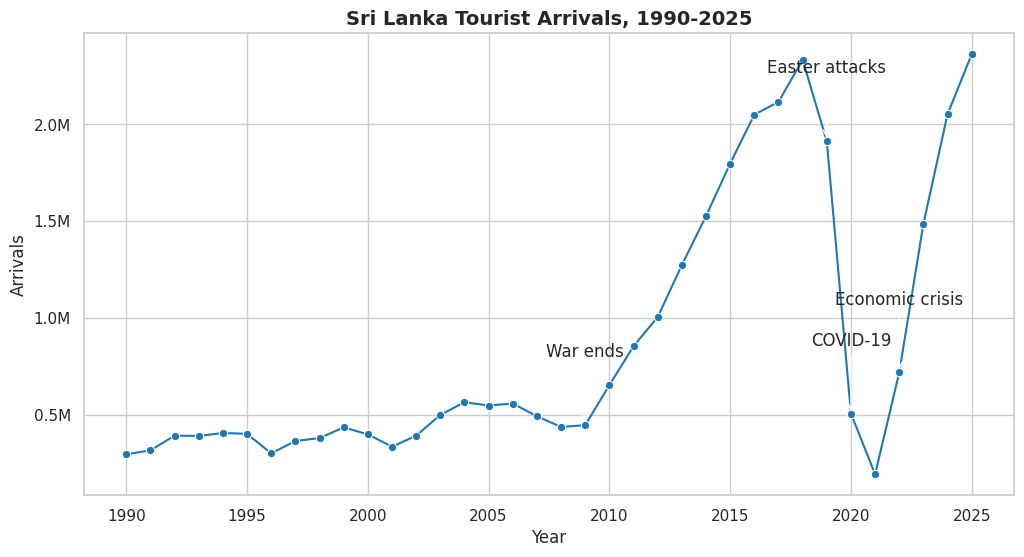

In [4]:
fig, ax = plt.subplots(figsize=(12, 6))
sns.lineplot(data=data, x='Year', y='Arrivals', marker='o', color='#1f77b4', ax=ax)

events = {2009: 'War ends', 2019: 'Easter attacks', 2020: 'COVID-19', 2022: 'Economic crisis'}
for yr, label in events.items():
    y = data.loc[data['Year'] == yr, 'Arrivals'].values[0]
    ax.annotate(label, xy=(yr, y), xytext=(yr, y + 350000),
                arrowprops=dict(arrowstyle='->'), ha='center')

ax.set_title('Sri Lanka Tourist Arrivals, 1990-2025', fontsize=14, fontweight='bold')
ax.set_ylabel('Arrivals')
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x/1e6:.1f}M'))
fig.savefig('/content/drive/MyDrive/Tourism project/chart1_arrivals.png', dpi=200, bbox_inches='tight')
plt.show()

**Insight:** Arrivals peaked at about 2.33 million in 2018, fell to about 194,000 in 2021, and reached about 2.36 million in 2025, the highest in the data.

**Chart 2: Are tourists spending more or less? (best insight)**

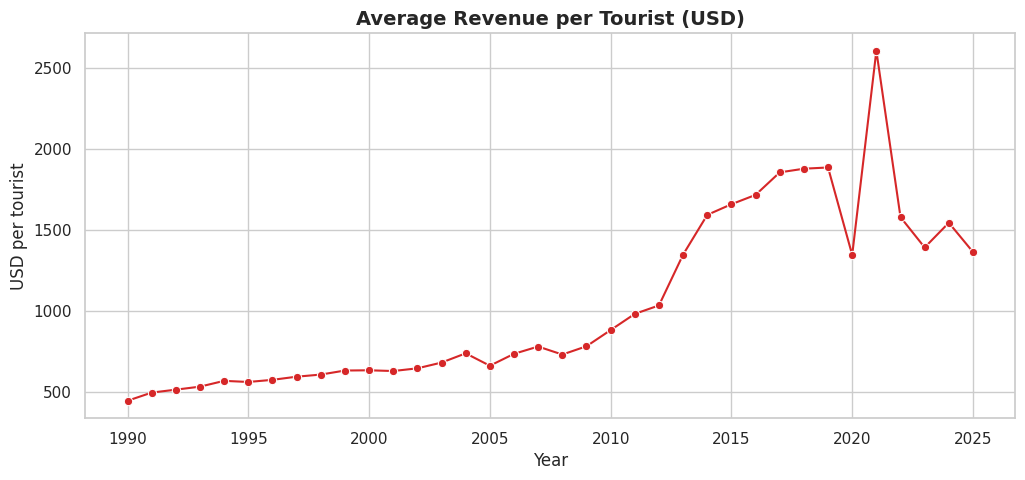

In [5]:
fig, ax = plt.subplots(figsize=(12, 5))
sns.lineplot(data=data, x='Year', y='USD_per_tourist', marker='o', color='#d62728', ax=ax)
ax.set_title('Average Revenue per Tourist (USD)', fontsize=14, fontweight='bold')
ax.set_ylabel('USD per tourist')
fig.savefig('/content/drive/MyDrive/Tourism project/chart2_spending.png', dpi=200, bbox_inches='tight')
plt.show()

**Insight:** Revenue per tourist fell from about $1,877 (2018) to about $1,363 (2025). The spike in 2021 (about $2,606) is not real spending growth. Only about 194,000 tourists arrived that year, which distorts the ratio.

**Chart 3: Hotel occupancy**

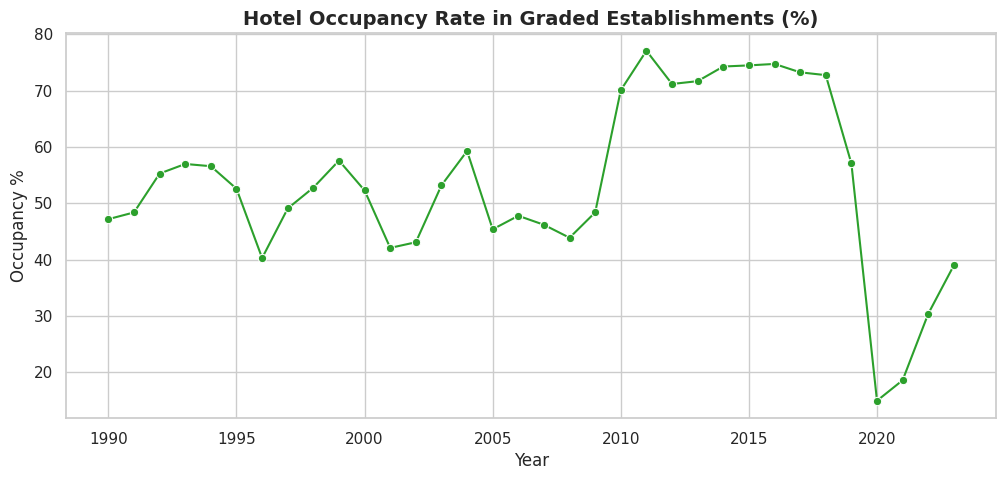

In [6]:
fig, ax = plt.subplots(figsize=(12, 5))
sns.lineplot(data=data, x='Year', y='Occupancy', marker='o', color='#2ca02c', ax=ax)
ax.set_title('Hotel Occupancy Rate in Graded Establishments (%)', fontsize=14, fontweight='bold')
ax.set_ylabel('Occupancy %')
fig.savefig('/content/drive/MyDrive/Tourism project/chart3_occupancy.png', dpi=200, bbox_inches='tight')
plt.show()

**Insight:** Hotel occupancy fell from 72.8% (2018) to 15% (2020) and had recovered to 39% by 2023. Data for 2024-2025 is not available.

**Chart 4: Yearly growth (ups and downs)**

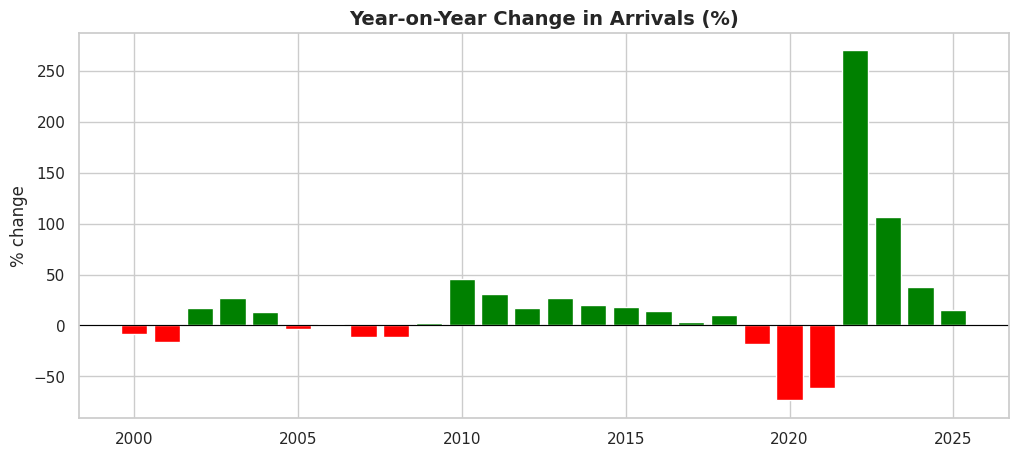

In [7]:
recent = data[data['Year'] >= 2000]
colors = ['green' if v >= 0 else 'red' for v in recent['Arrivals_YoY_%']]

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(recent['Year'], recent['Arrivals_YoY_%'], color=colors)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('Year-on-Year Change in Arrivals (%)', fontsize=14, fontweight='bold')
ax.set_ylabel('% change')
fig.savefig('/content/drive/MyDrive/Tourism project/chart4_growth.png', dpi=200, bbox_inches='tight')
plt.show()

**Insight:** Arrivals dropped 73% in 2020 and 62% in 2021, then rose 270% in 2022 and 107% in 2023. The huge rebound percentages are partly because they start from a very low base.

**Chart 5: Did tourism really recover? (arrivals vs revenue, 2018 = 100)**

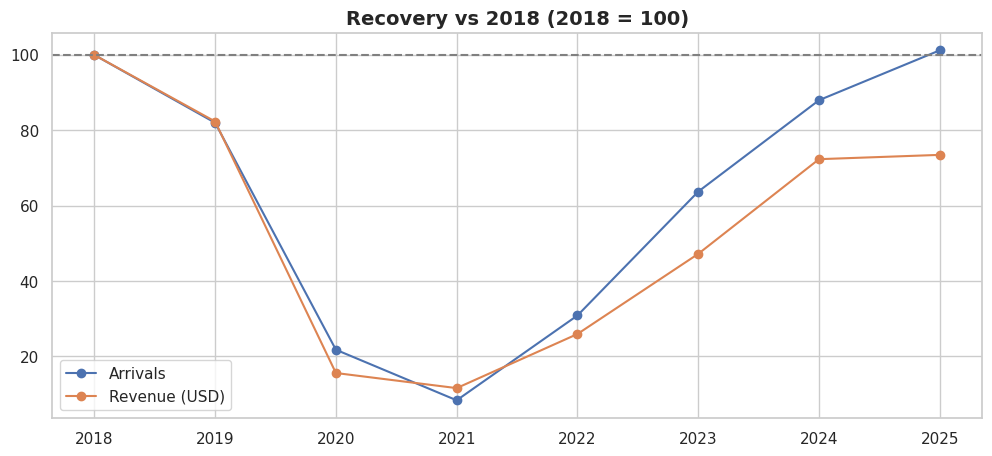

In [8]:
base = data[data['Year'] == 2018].iloc[0]
rec = data[data['Year'] >= 2018].copy()
rec['Arrivals index'] = rec['Arrivals'] / base['Arrivals'] * 100
rec['Revenue index'] = rec['Revenue_USD_m'] / base['Revenue_USD_m'] * 100

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(rec['Year'], rec['Arrivals index'], marker='o', label='Arrivals')
ax.plot(rec['Year'], rec['Revenue index'], marker='o', label='Revenue (USD)')
ax.axhline(100, color='grey', linestyle='--')
ax.set_title('Recovery vs 2018 (2018 = 100)', fontsize=14, fontweight='bold')
ax.legend()
fig.savefig('/content/drive/MyDrive/Tourism project/chart5_recovery.png', dpi=200, bbox_inches='tight')
plt.show()

**Insight:** In 2025, arrivals are at about 101% of the 2018 level, but revenue is only about 73%. Tourism has recovered in numbers, not in earnings.

**Data ready for Tableau**

In [9]:
base = data[data['Year'] == 2018].iloc[0]
data['Arrivals_index_2018'] = data['Arrivals'] / base['Arrivals'] * 100
data['Revenue_index_2018'] = data['Revenue_USD_m'] / base['Revenue_USD_m'] * 100

data.to_csv('tourism_clean.csv', index=False)

from google.colab import files
files.download('tourism_clean.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Part 2: Statistics and machine learning

## ML Step 1: Finding unusual years (anomaly detection)

**What I tried:** I measured the yearly % change in arrivals and used two methods to find unusual years: a z-score and an Isolation Forest.

**Result:** The z-score flagged only 2022 (z = 4.79). Isolation Forest flagged 2020, 2021, 2022 and 2023.

**What it means:** The huge 2022 jump (+270%) inflates the standard deviation (53%), so the z-score missed the 2020 and 2021 crashes (z = -1.66 and -1.44). Isolation Forest handled this better, but I set `contamination=0.1`, so it was always going to flag about 4 of the 35 years.

In [10]:
from sklearn.ensemble import IsolationForest

d = data[['Year', 'Arrivals_YoY_%']].dropna().copy()

# Method A: z-score
d['z_score'] = (d['Arrivals_YoY_%'] - d['Arrivals_YoY_%'].mean()) / d['Arrivals_YoY_%'].std()
d['z_flag'] = d['z_score'].abs() > 2

# Method B: Isolation Forest
iso_model = IsolationForest(contamination=0.1, random_state=42)
d['iso_flag'] = iso_model.fit_predict(d[['Arrivals_YoY_%']]) == -1

d[d['z_flag'] | d['iso_flag']]

,Year,Arrivals_YoY_%,z_score,z_flag,iso_flag
30,2020,-73.470060,-1.657780,False,True
31,2021,-61.691261,-1.436835,False,True
32,2022,270.178154,4.788332,True,True
33,2023,106.576173,1.719506,False,True


## ML Step 2: Forecasting arrivals with a time-based split

**What I tried:** I trained a log-linear regression on 1990-2018 and tested it on 2019-2025. I split by time, not randomly, because the future must never be used to predict the past.

**Result:** The trend shows about 6.9% growth per year (slope = 0.0664). On the test years the average error (MAE) was about 767,000 arrivals. For 2020 it predicted about 1.74 million, but the actual was about 508,000.

**What it means:** A trend model cannot predict shocks like COVID-19. However, by 2025 actual arrivals (2.36 million) were back to about 97% of the old trend line (2.43 million), so arrivals have returned to their pre-2019 path.

In [11]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

train = data[data['Year'] <= 2018]
test  = data[data['Year'] > 2018]

model = LinearRegression().fit(train[['Year']], np.log(train['Arrivals']))
pred = np.exp(model.predict(test[['Year']]))

print('MAE:', mean_absolute_error(test['Arrivals'], pred))
compare = test[['Year', 'Arrivals']].copy()
compare['Predicted'] = pred.round(0)
compare

MAE: 767385.913846195


,Year,Arrivals,Predicted
29,2019,1913702.0,1629105.0
30,2020,507704.0,1740996.0
31,2021,194495.0,1860572.0
32,2022,719978.0,1988361.0
33,2023,1487303.0,2124927.0
34,2024,2053465.0,2270872.0
35,2025,2362521.0,2426842.0


In [12]:
print('slope (beta1):', model.coef_[0])
print('intercept (beta0):', model.intercept_)
print('Growth per year %:', (np.exp(model.coef_[0]) - 1) * 100)

slope (beta1): 0.06642668840721438
intercept (beta0): -119.81194270426076
Growth per year %: 6.8682614378595686


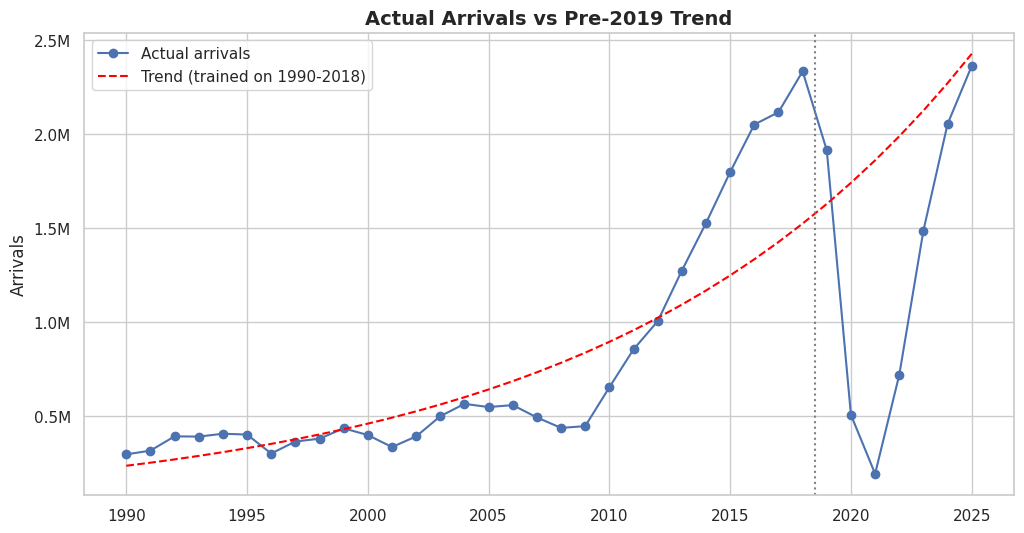

In [13]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(data['Year'], data['Arrivals'], marker='o', label='Actual arrivals')

trend = np.exp(model.predict(data[['Year']]))
ax.plot(data['Year'], trend, linestyle='--', color='red', label='Trend (trained on 1990-2018)')

ax.axvline(2018.5, color='grey', linestyle=':')
ax.set_title('Actual Arrivals vs Pre-2019 Trend', fontsize=14, fontweight='bold')
ax.set_ylabel('Arrivals')
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x/1e6:.1f}M'))
ax.legend()
fig.savefig('/content/drive/MyDrive/Tourism project/chart6_forecast.png', dpi=200, bbox_inches='tight')
plt.show()

**Insight:** The red line shows where arrivals would be if the pre-2019 trend had continued. Arrivals fell far below it in 2020-2022 but reached it again by 2025.

## ML Step 3: Predicting revenue from arrivals and occupancy

**What I tried:** I fitted a multiple regression (revenue = arrivals + occupancy) on 1991-2018 and tested it on 2019-2023.

**Result:** Train R² is about 0.99 and test R² is about 0.89, with an average error (MAE) of about $290 million.

**What it means:** Arrivals explain most of the changes in revenue. But the test set has only 5 years, and revenue is an estimate that is probably built from arrivals, so the high score is partly expected. The occupancy coefficient is negative because arrivals and occupancy rise together (multicollinearity), so it should not be read as "more occupancy lowers revenue".

In [14]:
from sklearn.metrics import r2_score

rev = data.dropna().copy()
rev['Arrivals_m'] = rev['Arrivals'] / 1e6

train_r = rev[rev['Year'] <= 2018]
test_r  = rev[rev['Year'] > 2018]
features = ['Arrivals_m', 'Occupancy']

reg = LinearRegression().fit(train_r[features], train_r['Revenue_USD_m'])
pred_r = reg.predict(test_r[features])

print('Intercept (b0):', reg.intercept_)
print('Arrivals_m (b1):', reg.coef_[0])
print('Occupancy (b2):', reg.coef_[1])
print('Train R2:', r2_score(train_r['Revenue_USD_m'], reg.predict(train_r[features])))
print('Test R2:', r2_score(test_r['Revenue_USD_m'], pred_r))
print('Test MAE:', mean_absolute_error(test_r['Revenue_USD_m'], pred_r))

Intercept (b0): -23.45670248310796
Arrivals_m (b1): 2245.0757032412034
Occupancy (b2): -13.312886028408169
Train R2: 0.9922792902323235
Test R2: 0.8901670406354144
Test MAE: 290.1611142937835


## Conclusion

- Arrivals in 2025 (about 2.36 million) are back to the 2018 level and to the pre-2019 growth trend.
- Revenue in 2025 is only about 73% of 2018, and revenue per tourist fell from about $1,877 to about $1,363.
- **Recommendation:** Focus on increasing spending per tourist (longer stays, higher-value tourism), not only on increasing arrivals.

**Limits:** Only 36 yearly data points; revenue is an estimate; occupancy is missing for 2024-2025; ML models trained on this little data are only indicative.